In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

In [16]:
df=pd.read_csv('income.csv')
df.head()

,Name,x,y
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000


In [17]:
p=df[['x','y']]

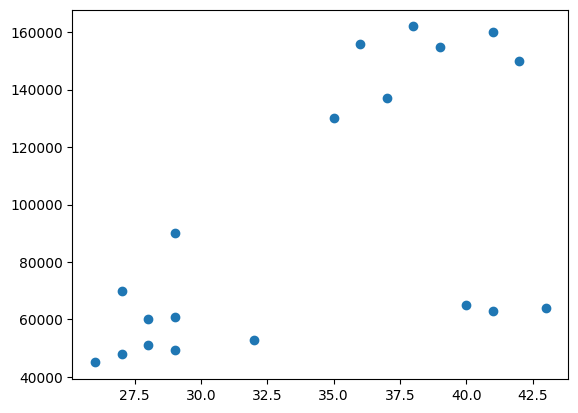

In [18]:
plt.scatter(df.x,df.y)

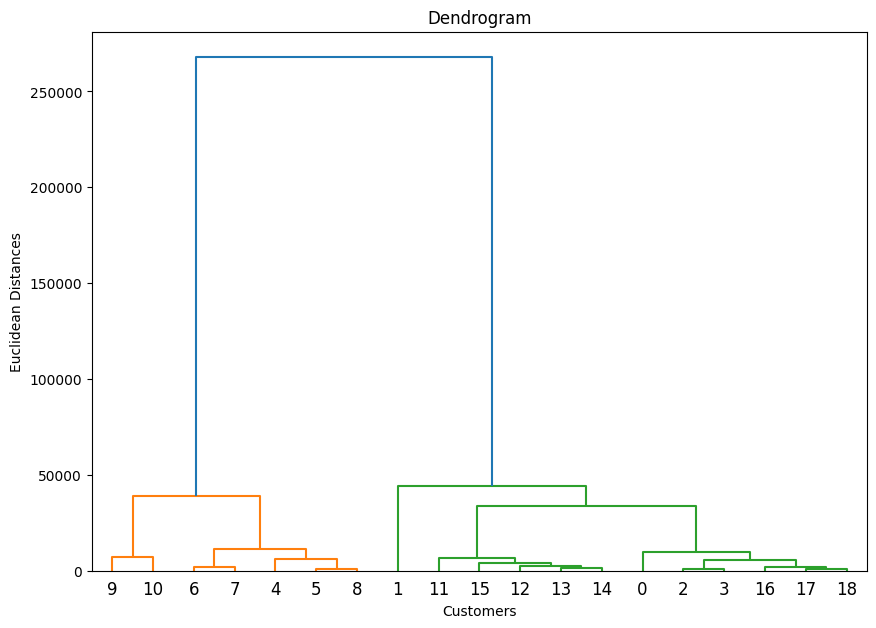

In [19]:
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(10,7))

linked = sch.linkage(p, method='ward')

sch.dendrogram(linked)

plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean Distances')
plt.show()

In [20]:
from sklearn.preprocessing import MinMaxScaler
sc=MinMaxScaler()
p=sc.fit_transform(p)
cl=AgglomerativeClustering(n_clusters=3,linkage='ward')
clust=cl.fit_predict(p)
clust

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2])

In [21]:
df['clust']=clust

In [22]:
df.head()

,Name,x,y,clust
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,0


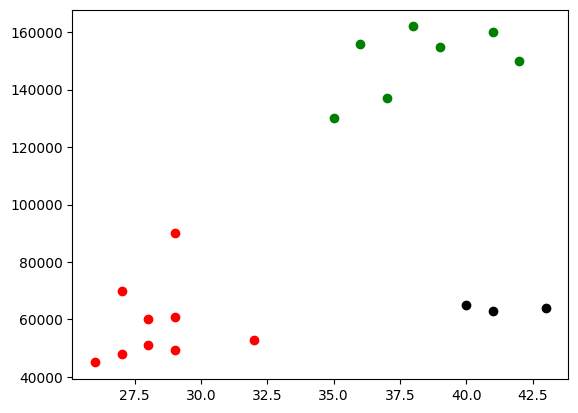

In [24]:
df1=df[df.clust==0]
df2=df[df.clust==1]
df3=df[df.clust==2]
plt.scatter(df1.x,df1.y,color="green")
plt.scatter(df2.x,df2.y,color="red")
plt.scatter(df3.x,df3.y,color="black")

In [25]:
from sklearn.metrics import silhouette_score
silhouette_score(p,clust)

0.7340476081175014

In [28]:


# 2. Train KNN using Agglomerative labels
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(p, clust)

# 3. New user input
age = float(input("Enter Age: "))
income = float(input("Enter Income: "))

new_data = sc.transform([[age, income]])

# 4. Predict
pred = knn.predict(new_data)

print("Cluster:", pred[0])

Cluster: 1


c:\Users\VIVEK V\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
